# IMDB Sentiment Analysis: Logistic Regression vs LSTM vs Vanilla Transformer vs BERT

**Task:** Binary sentiment classification (positive / negative) on the 50,000-review IMDB dataset.

| # | Model | Type | Text representation |
|---|-------|------|---------------------|
| 1 | Logistic Regression | Classical ML baseline | TF-IDF (1-2 grams) |
| 2 | Bi-LSTM | Recurrent DL, trained from scratch | Learned word embeddings |
| 3 | Vanilla Transformer | Encoder-only Transformer, trained from scratch | Learned embeddings + sinusoidal positions |
| 4 | BERT (`bert-base-uncased`) | Pretrained Transformer, fine-tuned | WordPiece + pretrained weights |

**Evaluation:** Accuracy, Precision, Recall, F1 (macro), confusion matrices, ROC curves, efficiency (params / train time / inference time) and error analysis.

> **Runtime:** use a GPU (`Runtime > Change runtime type > T4 GPU`). Total run time is roughly 25-35 minutes on a T4, and BERT is most of it.

## 1. Setup

In [1]:
!pip install -q transformers

In [2]:
import os, re, time, random, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, auc)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

# ------------------------- CONFIG -------------------------
SEED          = 42
SMOKE_TEST    = False     # True = tiny subset + 1 epoch, just to check the notebook runs end-to-end
MAX_LEN       = 256       # token length for LSTM / Transformer
MAX_VOCAB     = 30000
BERT_MAX_LEN  = 256
BERT_EPOCHS   = 2
BERT_BATCH    = 32
DL_EPOCHS     = 8         # LSTM / Transformer (early stopping on validation F1)
# ----------------------------------------------------------

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU (training will be very slow)")

Device: cuda | Tesla T4


## 2. Load and preprocess data

In [4]:
CSV_PATH = "IMDB_Dataset.csv"
if not os.path.exists(CSV_PATH):
    try:   # option A: file stored in Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        CSV_PATH = "/content/drive/MyDrive/IMDB_Dataset.csv"   # <-- change if your path differs
        assert os.path.exists(CSV_PATH)
    except Exception:      # option B: upload manually
        from google.colab import files
        up = files.upload()
        CSV_PATH = list(up.keys())[0]

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving IMDB Dataset.csv to IMDB Dataset (1).csv
(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


Rows after de-duplication: 49578
label
positive    24882
negative    24696
Name: count, dtype: int64
count    49578.0
mean       229.1
std        169.8
min          4.0
25%        125.0
50%        172.0
75%        278.0
max       2459.0
Name: n_words, dtype: float64


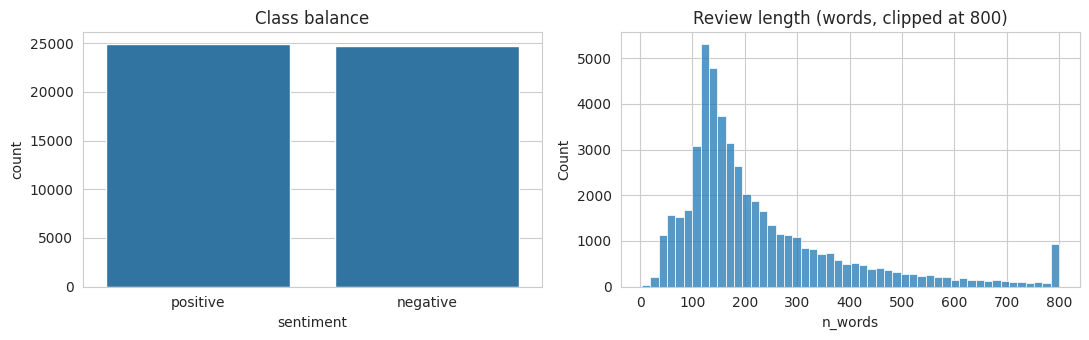

In [5]:
def clean_text(t):
    t = re.sub(r"<.*?>", " ", t)          # strip HTML tags such as <br />
    t = re.sub(r"\s+", " ", t).strip()
    return t

df["review"] = df["review"].astype(str).map(clean_text)
df["label"]  = (df["sentiment"].str.lower() == "positive").astype(int)
df = df.drop_duplicates(subset="review").reset_index(drop=True)

if SMOKE_TEST:
    df = df.sample(3000, random_state=SEED).reset_index(drop=True)

print("Rows after de-duplication:", len(df))
print(df["label"].value_counts().rename({1: "positive", 0: "negative"}))
df["n_words"] = df["review"].str.split().str.len()
print(df["n_words"].describe().round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.countplot(x="sentiment", data=df, ax=ax[0]); ax[0].set_title("Class balance")
sns.histplot(df["n_words"].clip(upper=800), bins=50, ax=ax[1]); ax[1].set_title("Review length (words, clipped at 800)")
plt.tight_layout(); plt.show()

In [6]:
# Stratified 80 / 10 / 10 split. The same split is used by every model.
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
val_df,   test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["label"], random_state=SEED)
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")

y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values

train=39662  val=4958  test=4958


## 3. Evaluation utilities

In [7]:
RESULTS = {}          # model name -> metrics dict
CLASS_NAMES = ["negative", "positive"]

def evaluate_model(name, y_true, y_prob, train_time, infer_time, n_params, threshold=0.5):
    # y_prob = P(positive). Stores metrics and plots the confusion matrix.
    y_pred = (y_prob >= threshold).astype(int)
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    RESULTS[name] = dict(
        Accuracy  = accuracy_score(y_true, y_pred),
        Precision = precision_score(y_true, y_pred, average="macro"),
        Recall    = recall_score(y_true, y_pred, average="macro"),
        F1        = f1_score(y_true, y_pred, average="macro"),
        AUC       = auc(fpr, tpr),
        cm        = confusion_matrix(y_true, y_pred),
        y_pred    = y_pred, y_prob = y_prob, fpr = fpr, tpr = tpr,
        train_time_s = train_time, infer_ms_per_1k = infer_time / len(y_true) * 1000 * 1000,
        params    = n_params,
    )
    print(f"===== {name} (test set) =====")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
    cm = RESULTS[name]["cm"]
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0])
    ax[0].set_title(f"{name}: counts"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2%", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1])
    ax[1].set_title(f"{name}: row-normalised"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")
    plt.tight_layout(); plt.show()

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

## 4. Model 1: Logistic Regression (TF-IDF)
A strong, cheap baseline. Uni+bi-grams capture short phrases such as "not good" or "waste of time".

C=0.5  val macro-F1 = 0.8969
C=1    val macro-F1 = 0.9038
C=2    val macro-F1 = 0.9082
C=5    val macro-F1 = 0.9137
C=10   val macro-F1 = 0.9141
Best C: 10
===== Logistic Regression (test set) =====
              precision    recall  f1-score   support

    negative     0.9302    0.9016    0.9157      2470
    positive     0.9052    0.9329    0.9188      2488

    accuracy                         0.9173      4958
   macro avg     0.9177    0.9172    0.9173      4958
weighted avg     0.9177    0.9173    0.9173      4958



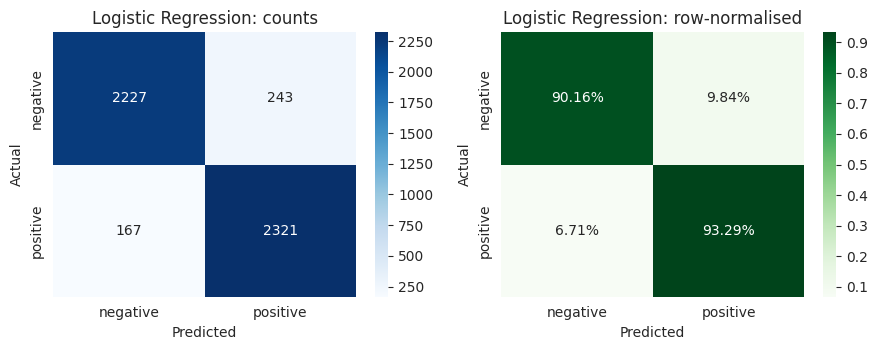

In [8]:
t0 = time.time()
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=300_000,
                        sublinear_tf=True, stop_words=None)
Xtr = tfidf.fit_transform(train_df["review"])
Xva = tfidf.transform(val_df["review"])
Xte = tfidf.transform(test_df["review"])

# pick C on the validation set
best_C, best_f1, best_lr = None, -1, None
for C in [0.5, 1, 2, 5, 10]:
    lr = LogisticRegression(C=C, max_iter=2000, solver="liblinear", random_state=SEED).fit(Xtr, y_train)
    f = f1_score(y_val, lr.predict(Xva), average="macro")
    print(f"C={C:<4} val macro-F1 = {f:.4f}")
    if f > best_f1: best_C, best_f1, best_lr = C, f, lr
lr_train_time = time.time() - t0
print("Best C:", best_C)

t0 = time.time()
lr_prob = best_lr.predict_proba(Xte)[:, 1]
lr_infer_time = time.time() - t0

evaluate_model("Logistic Regression", y_test, lr_prob, lr_train_time, lr_infer_time,
               n_params=best_lr.coef_.size + 1)

In [9]:
# Interpretability: most influential words/phrases
fn = np.array(tfidf.get_feature_names_out()); coef = best_lr.coef_[0]
top_pos = fn[np.argsort(coef)[-15:][::-1]]; top_neg = fn[np.argsort(coef)[:15]]
print("Top positive:", ", ".join(top_pos)); print("Top negative:", ", ".join(top_neg))

Top positive: great, excellent, perfect, amazing, wonderful, enjoyable, best, hilarious, brilliant, today, the best, superb, loved, fun, enjoyed
Top negative: worst, bad, awful, boring, the worst, waste, poor, terrible, worse, nothing, horrible, stupid, poorly, dull, disappointment


## 5. Tokenisation for the from-scratch neural models (LSTM and Transformer)
A simple word-level vocabulary is built from the **training set only** (no leakage). Index 0 = `<pad>`, 1 = `<unk>`.

In [10]:
def tokenize(t): return re.findall(r"[a-z0-9']+|[!?]", t.lower())

counter = Counter(tok for r in train_df["review"] for tok in tokenize(r))
itos = ["<pad>", "<unk>"] + [w for w, c in counter.most_common(MAX_VOCAB - 2) if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)
print("Vocab size:", VOCAB_SIZE)

def encode(texts, max_len=MAX_LEN):
    out = np.zeros((len(texts), max_len), dtype=np.int64)
    for i, t in enumerate(texts):
        ids = [stoi.get(w, 1) for w in tokenize(t)][:max_len]
        out[i, :len(ids)] = ids
    return torch.from_numpy(out)

Xtr_ids, Xva_ids, Xte_ids = (encode(d["review"].tolist()) for d in (train_df, val_df, test_df))
ytr_t, yva_t, yte_t = (torch.tensor(y, dtype=torch.long) for y in (y_train, y_val, y_test))

BATCH = 64
train_loader = DataLoader(TensorDataset(Xtr_ids, ytr_t), batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(TensorDataset(Xva_ids, yva_t), batch_size=256)
test_loader  = DataLoader(TensorDataset(Xte_ids, yte_t), batch_size=256)
print("Share of reviews truncated at MAX_LEN:", f"{(df['n_words'] > MAX_LEN).mean():.1%}")

Vocab size: 30000
Share of reviews truncated at MAX_LEN: 28.2%


### Shared training / prediction loop (used by LSTM and Transformer)

In [11]:
@torch.no_grad()
def predict_proba(model, loader):
    model.eval(); probs = []
    for xb, _ in loader:
        logits = model(xb.to(DEVICE))
        probs.append(F.softmax(logits, dim=-1)[:, 1].cpu())
    return torch.cat(probs).numpy()

def train_model(model, epochs, lr, weight_decay=0.01, warmup_frac=0.0, patience=3, tag="model"):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    total = epochs * len(train_loader); warm = int(warmup_frac * total)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / max(1, warm) if s < warm else max(0.0, (total - s) / max(1, total - warm)))
    best_f1, best_state, bad = -1, None, 0
    hist = dict(train_loss=[], val_f1=[], val_acc=[])
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); run = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); run += loss.item() * len(xb)
        vp = predict_proba(model, val_loader); vpred = (vp >= 0.5).astype(int)
        vf1, vacc = f1_score(y_val, vpred, average="macro"), accuracy_score(y_val, vpred)
        hist["train_loss"].append(run / len(train_loader.dataset)); hist["val_f1"].append(vf1); hist["val_acc"].append(vacc)
        print(f"[{tag}] epoch {ep}/{epochs}  train_loss={hist['train_loss'][-1]:.4f}  val_F1={vf1:.4f}  val_acc={vacc:.4f}  ({time.time()-t0:.0f}s)")
        if vf1 > best_f1: best_f1, best_state, bad = vf1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: print("Early stopping."); break
    model.load_state_dict(best_state)
    return hist, time.time() - t0

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(h["train_loss"], marker="o"); ax[0].set_title(f"{title}: train loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(h["val_f1"], marker="o", label="val F1"); ax[1].plot(h["val_acc"], marker="s", label="val acc")
    ax[1].set_title(f"{title}: validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

def test_and_evaluate(name, model, train_time):
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time(); prob = predict_proba(model, test_loader)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    evaluate_model(name, y_test, prob, train_time, time.time() - t0, count_params(model))

## 6. Model 2: Bi-LSTM
Embedding -> 2-layer bidirectional LSTM (padding handled with packed sequences) -> concatenated final forward/backward hidden states -> dropout -> linear classifier.

Trainable parameters: 4,499,970
[BiLSTM] epoch 1/8  train_loss=0.5757  val_F1=0.8084  val_acc=0.8084  (29s)
[BiLSTM] epoch 2/8  train_loss=0.3920  val_F1=0.8655  val_acc=0.8657  (57s)
[BiLSTM] epoch 3/8  train_loss=0.2901  val_F1=0.8888  val_acc=0.8889  (85s)
[BiLSTM] epoch 4/8  train_loss=0.2451  val_F1=0.8943  val_acc=0.8945  (113s)
[BiLSTM] epoch 5/8  train_loss=0.2103  val_F1=0.9009  val_acc=0.9010  (141s)
[BiLSTM] epoch 6/8  train_loss=0.1887  val_F1=0.8995  val_acc=0.8996  (169s)
[BiLSTM] epoch 7/8  train_loss=0.1681  val_F1=0.9036  val_acc=0.9036  (197s)
[BiLSTM] epoch 8/8  train_loss=0.1559  val_F1=0.9050  val_acc=0.9050  (226s)


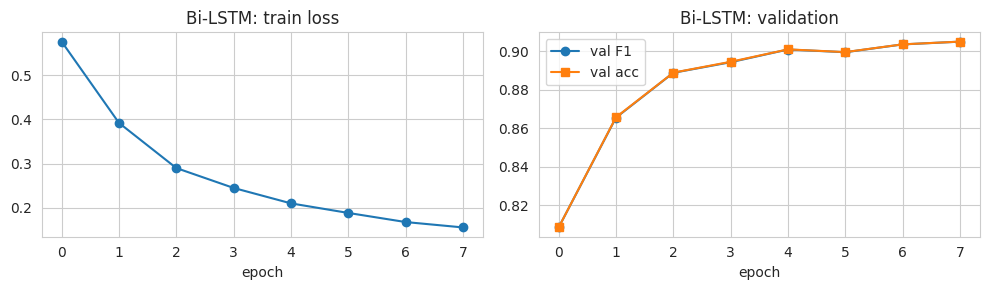

===== Bi-LSTM (test set) =====
              precision    recall  f1-score   support

    negative     0.9182    0.8907    0.9042      2470
    positive     0.8946    0.9212    0.9077      2488

    accuracy                         0.9060      4958
   macro avg     0.9064    0.9060    0.9060      4958
weighted avg     0.9064    0.9060    0.9060      4958



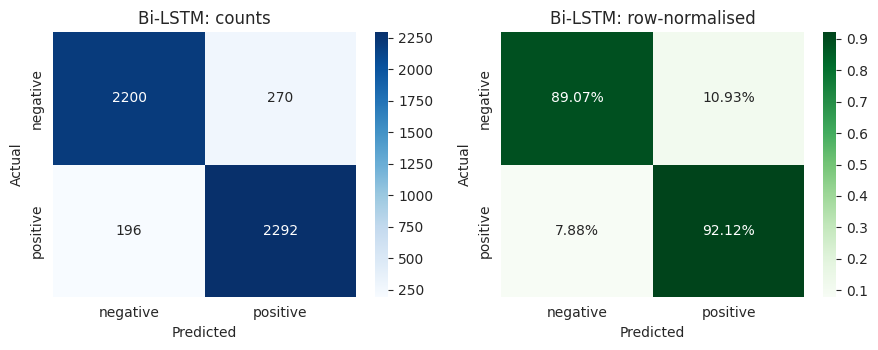

In [12]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128, layers=2, dropout=0.4, n_classes=2):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, num_layers=layers, batch_first=True,
                            bidirectional=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(hidden * 2, n_classes)

    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h = torch.cat([h[-2], h[-1]], dim=1)      # last layer: forward + backward
        return self.fc(self.drop(h))

set_seed()
lstm_model = BiLSTMClassifier(VOCAB_SIZE)
print("Trainable parameters:", f"{count_params(lstm_model):,}")
lstm_hist, lstm_time = train_model(lstm_model, epochs=1 if SMOKE_TEST else DL_EPOCHS, lr=2e-3, tag="BiLSTM")
plot_history(lstm_hist, "Bi-LSTM")
test_and_evaluate("Bi-LSTM", lstm_model, lstm_time)

## 7. Model 3: Vanilla Transformer (encoder-only, from scratch)
The architecture follows *Attention Is All You Need* (encoder stack): token embedding scaled by sqrt(d_model), **sinusoidal positional encoding**, N x [multi-head self-attention + feed-forward, with residuals and layer-norm], padding mask, masked mean-pooling, linear classifier. **No pretrained weights.**

Trainable parameters: 4,236,802
[Transformer] epoch 1/8  train_loss=0.5530  val_F1=0.7973  val_acc=0.7983  (26s)
[Transformer] epoch 2/8  train_loss=0.4097  val_F1=0.8260  val_acc=0.8261  (52s)
[Transformer] epoch 3/8  train_loss=0.3682  val_F1=0.8262  val_acc=0.8273  (78s)
[Transformer] epoch 4/8  train_loss=0.3404  val_F1=0.8501  val_acc=0.8501  (104s)
[Transformer] epoch 5/8  train_loss=0.3184  val_F1=0.8557  val_acc=0.8558  (130s)
[Transformer] epoch 6/8  train_loss=0.3022  val_F1=0.8579  val_acc=0.8580  (156s)
[Transformer] epoch 7/8  train_loss=0.2869  val_F1=0.8619  val_acc=0.8620  (182s)
[Transformer] epoch 8/8  train_loss=0.2771  val_F1=0.8632  val_acc=0.8633  (208s)


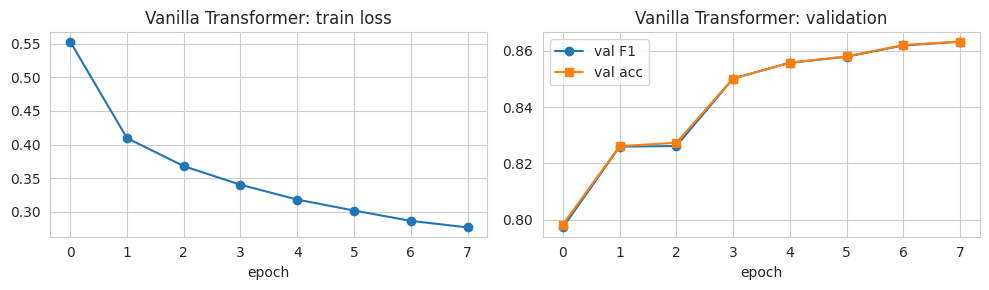

===== Vanilla Transformer (test set) =====
              precision    recall  f1-score   support

    negative     0.8765    0.8563    0.8663      2470
    positive     0.8605    0.8802    0.8703      2488

    accuracy                         0.8683      4958
   macro avg     0.8685    0.8683    0.8683      4958
weighted avg     0.8685    0.8683    0.8683      4958



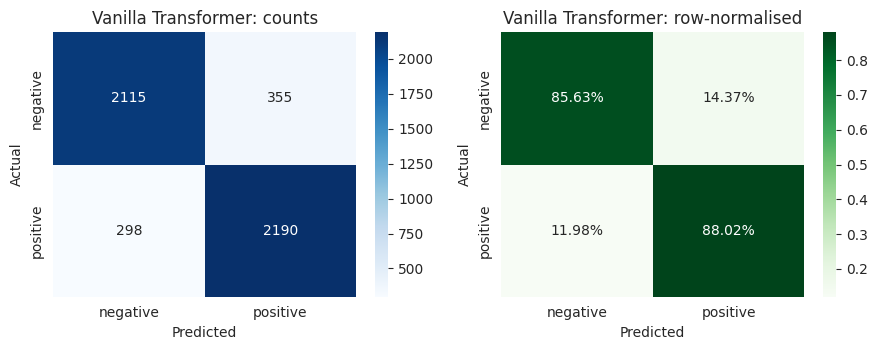

In [13]:
import math

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x): return x + self.pe[:, :x.size(1)]

class VanillaTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, nhead=4, ff=512, layers=2, dropout=0.1, n_classes=2, max_len=512):
        super().__init__()
        self.d_model = d_model
        self.emb  = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.pos  = PositionalEncoding(d_model, max_len)
        self.drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(d_model, nhead, ff, dropout, batch_first=True, activation="gelu")
        self.enc  = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.fc   = nn.Linear(d_model, n_classes)

    def forward(self, x):
        pad = (x == 0)                                         # True where padded
        h = self.drop(self.pos(self.emb(x) * math.sqrt(self.d_model)))
        h = self.enc(h, src_key_padding_mask=pad)
        keep = (~pad).unsqueeze(-1).float()
        h = (h * keep).sum(1) / keep.sum(1).clamp(min=1)       # masked mean pooling
        return self.fc(self.drop(h))

set_seed()
tf_model = VanillaTransformerClassifier(VOCAB_SIZE)
print("Trainable parameters:", f"{count_params(tf_model):,}")
tf_hist, tf_time = train_model(tf_model, epochs=1 if SMOKE_TEST else DL_EPOCHS, lr=5e-4,
                               warmup_frac=0.1, tag="Transformer")
plot_history(tf_hist, "Vanilla Transformer")
test_and_evaluate("Vanilla Transformer", tf_model, tf_time)

## 8. Model 4: BERT (`bert-base-uncased`), pretrained and fine-tuned
The model arrives with language knowledge from pre-training on BooksCorpus and Wikipedia. It is fine-tuned end to end with a small learning rate (2e-5), linear warm-up/decay and mixed precision (fp16) for speed.

In [14]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

BERT_NAME = "bert-base-uncased"
bert_tok = AutoTokenizer.from_pretrained(BERT_NAME)

def bert_encode(texts):
    enc = bert_tok(texts, truncation=True, max_length=BERT_MAX_LEN, padding="max_length", return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]

t0 = time.time()
b_tr_ids, b_tr_mask = bert_encode(train_df["review"].tolist())
b_va_ids, b_va_mask = bert_encode(val_df["review"].tolist())
b_te_ids, b_te_mask = bert_encode(test_df["review"].tolist())
print(f"Tokenised in {time.time()-t0:.0f}s")

bert_train_loader = DataLoader(TensorDataset(b_tr_ids, b_tr_mask, ytr_t), batch_size=BERT_BATCH, shuffle=True)
bert_val_loader   = DataLoader(TensorDataset(b_va_ids, b_va_mask, yva_t), batch_size=128)
bert_test_loader  = DataLoader(TensorDataset(b_te_ids, b_te_mask, yte_t), batch_size=128)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenised in 68s


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 step 200/1240  loss=0.1974  (82s)
  epoch 1 step 400/1240  loss=0.1178  (163s)
  epoch 1 step 600/1240  loss=0.2587  (244s)
  epoch 1 step 800/1240  loss=0.3897  (325s)
  epoch 1 step 1000/1240  loss=0.3894  (406s)
  epoch 1 step 1200/1240  loss=0.0669  (487s)
[BERT] epoch 1/2  train_loss=0.2774  val_F1=0.9322  val_acc=0.9322  (521s)
  epoch 2 step 200/1240  loss=0.1480  (603s)
  epoch 2 step 400/1240  loss=0.1577  (684s)
  epoch 2 step 600/1240  loss=0.0104  (765s)
  epoch 2 step 800/1240  loss=0.0577  (846s)
  epoch 2 step 1000/1240  loss=0.2184  (927s)
  epoch 2 step 1200/1240  loss=0.2565  (1008s)
[BERT] epoch 2/2  train_loss=0.1392  val_F1=0.9338  val_acc=0.9338  (1042s)


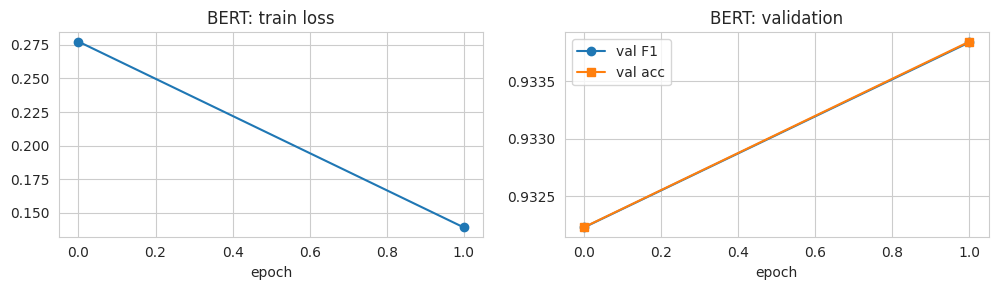

In [15]:
from transformers import get_linear_schedule_with_warmup

@torch.no_grad()
def bert_predict_proba(model, loader):
    model.eval(); probs = []
    for ids, mask, _ in loader:
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = model(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).logits
        probs.append(F.softmax(logits.float(), dim=-1)[:, 1].cpu())
    return torch.cat(probs).numpy()

set_seed()
bert = AutoModelForSequenceClassification.from_pretrained(BERT_NAME, num_labels=2).to(DEVICE)
epochs = 1 if SMOKE_TEST else BERT_EPOCHS
opt = torch.optim.AdamW(bert.parameters(), lr=2e-5, weight_decay=0.01)
total_steps = epochs * len(bert_train_loader)
sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

bert_hist = dict(train_loss=[], val_f1=[], val_acc=[])
best_f1, best_state = -1, None
t0 = time.time()
for ep in range(1, epochs + 1):
    bert.train(); run = 0.0
    for step, (ids, mask, yb) in enumerate(bert_train_loader, 1):
        ids, mask, yb = ids.to(DEVICE), mask.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad()
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            loss = F.cross_entropy(bert(input_ids=ids, attention_mask=mask).logits.float(), yb)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(bert.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.item() * len(yb)
        if step % 200 == 0: print(f"  epoch {ep} step {step}/{len(bert_train_loader)}  loss={loss.item():.4f}  ({time.time()-t0:.0f}s)")
    vp = bert_predict_proba(bert, bert_val_loader); vpred = (vp >= 0.5).astype(int)
    vf1, vacc = f1_score(y_val, vpred, average="macro"), accuracy_score(y_val, vpred)
    bert_hist["train_loss"].append(run / len(bert_train_loader.dataset)); bert_hist["val_f1"].append(vf1); bert_hist["val_acc"].append(vacc)
    print(f"[BERT] epoch {ep}/{epochs}  train_loss={bert_hist['train_loss'][-1]:.4f}  val_F1={vf1:.4f}  val_acc={vacc:.4f}  ({time.time()-t0:.0f}s)")
    if vf1 > best_f1: best_f1, best_state = vf1, {k: v.detach().cpu().clone() for k, v in bert.state_dict().items()}
bert_time = time.time() - t0
bert.load_state_dict(best_state)
plot_history(bert_hist, "BERT")

===== BERT (test set) =====
              precision    recall  f1-score   support

    negative     0.9337    0.9186    0.9261      2470
    positive     0.9205    0.9353    0.9278      2488

    accuracy                         0.9270      4958
   macro avg     0.9271    0.9270    0.9270      4958
weighted avg     0.9271    0.9270    0.9270      4958



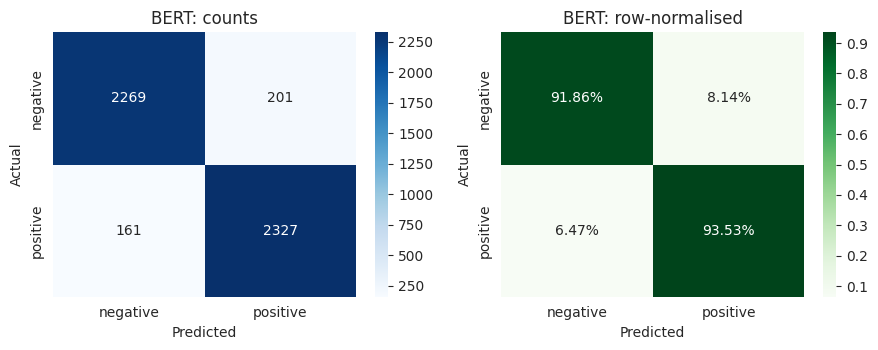

In [16]:
if DEVICE.type == "cuda": torch.cuda.synchronize()
t0 = time.time(); bert_prob = bert_predict_proba(bert, bert_test_loader)
if DEVICE.type == "cuda": torch.cuda.synchronize()
evaluate_model("BERT", y_test, bert_prob, bert_time, time.time() - t0, count_params(bert))

## 9. Comparative analysis

### 9.1 Metrics summary (test set)

,Accuracy,Precision,Recall,F1,AUC
Logistic Regression,0.9173,0.9177,0.9172,0.9173,0.9730
Bi-LSTM,0.9060,0.9064,0.9060,0.9060,0.9668
Vanilla Transformer,0.8683,0.8685,0.8683,0.8683,0.9390
BERT,0.9270,0.9271,0.9270,0.9270,0.9791


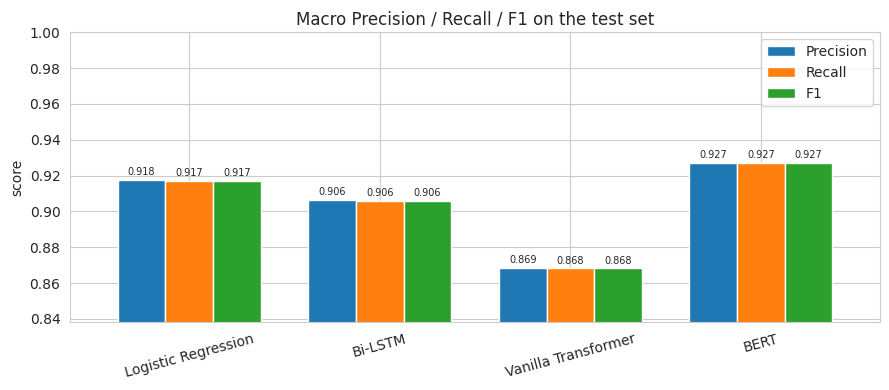

In [17]:
order = ["Logistic Regression", "Bi-LSTM", "Vanilla Transformer", "BERT"]
summary = pd.DataFrame({m: {k: RESULTS[m][k] for k in ["Accuracy", "Precision", "Recall", "F1", "AUC"]} for m in order}).T
summary_disp = summary.copy()
display(summary_disp.style.format("{:.4f}").highlight_max(axis=0, color="#c6efce"))
summary.to_csv("model_comparison_metrics.csv")

ax = summary[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4), width=0.75, rot=15)
lo = max(0.0, summary[["Precision", "Recall", "F1"]].min().min() - 0.03)
ax.set_ylim(lo, 1.0); ax.set_title("Macro Precision / Recall / F1 on the test set"); ax.set_ylabel("score")
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2)
plt.tight_layout(); plt.show()

### 9.2 Confusion matrices side by side

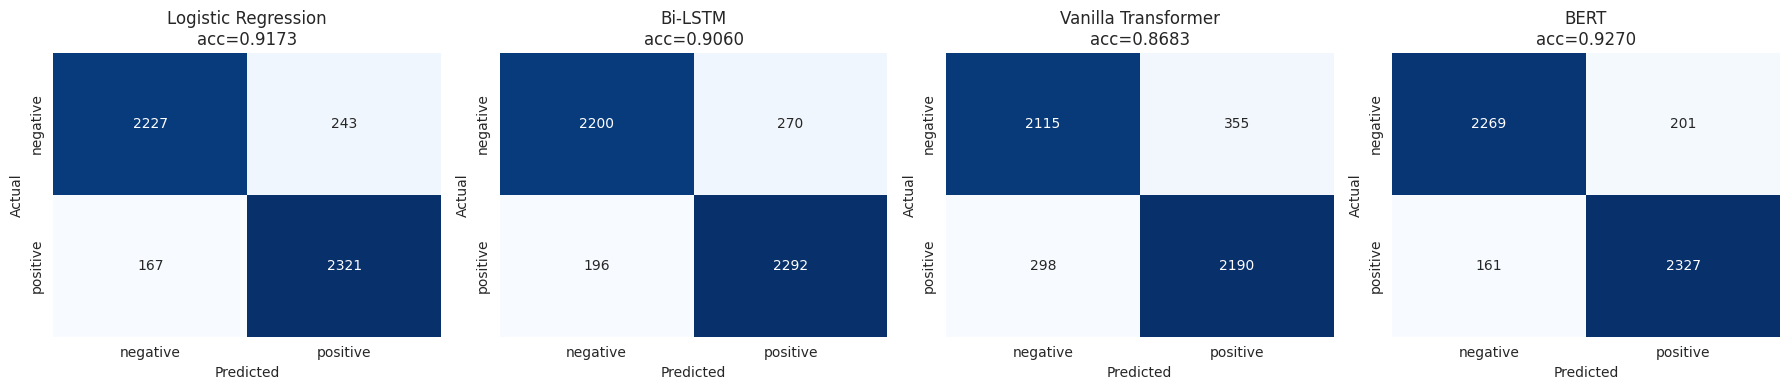

,TN,FP,FN,TP,FP_rate,FN_rate,Total_errors
Model,,,,,,,
Logistic Regression,2227,243,167,2321,9.84%,6.71%,410
Bi-LSTM,2200,270,196,2292,10.93%,7.88%,466
Vanilla Transformer,2115,355,298,2190,14.37%,11.98%,653
BERT,2269,201,161,2327,8.14%,6.47%,362


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m in zip(axes, order):
    cm = RESULTS[m]["cm"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{m}\nacc={RESULTS[m]['Accuracy']:.4f}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

# Error profile: which kind of mistake does each model make?
rows = []
for m in order:
    tn, fp, fn, tp = RESULTS[m]["cm"].ravel()
    rows.append(dict(Model=m, TN=tn, FP=fp, FN=fn, TP=tp,
                     FP_rate=fp / (fp + tn), FN_rate=fn / (fn + tp), Total_errors=fp + fn))
err = pd.DataFrame(rows).set_index("Model")
display(err.style.format({"FP_rate": "{:.2%}", "FN_rate": "{:.2%}"}))

### 9.3 ROC curves

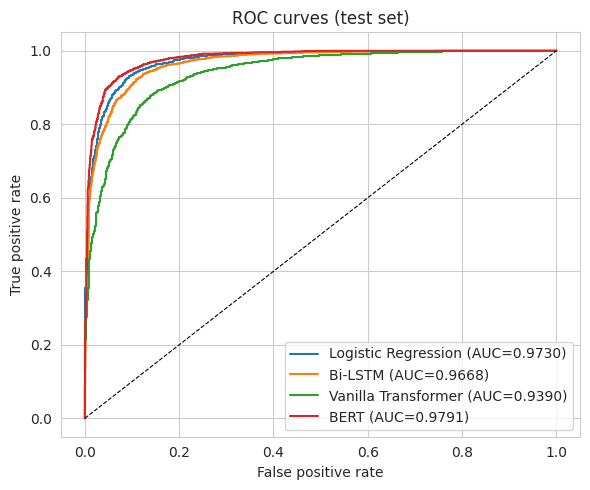

In [19]:
plt.figure(figsize=(6, 5))
for m in order:
    plt.plot(RESULTS[m]["fpr"], RESULTS[m]["tpr"], label=f"{m} (AUC={RESULTS[m]['AUC']:.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves (test set)")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 9.4 Efficiency: parameters, training time, inference speed

,Parameters,Train_time_min,Inference_s_per_1k_reviews,F1
Logistic Regression,"300,001",1.12,0.001,0.9173
Bi-LSTM,"4,499,970",3.77,0.122,0.9060
Vanilla Transformer,"4,236,802",3.46,0.179,0.8683
BERT,"109,483,778",17.38,3.746,0.9270


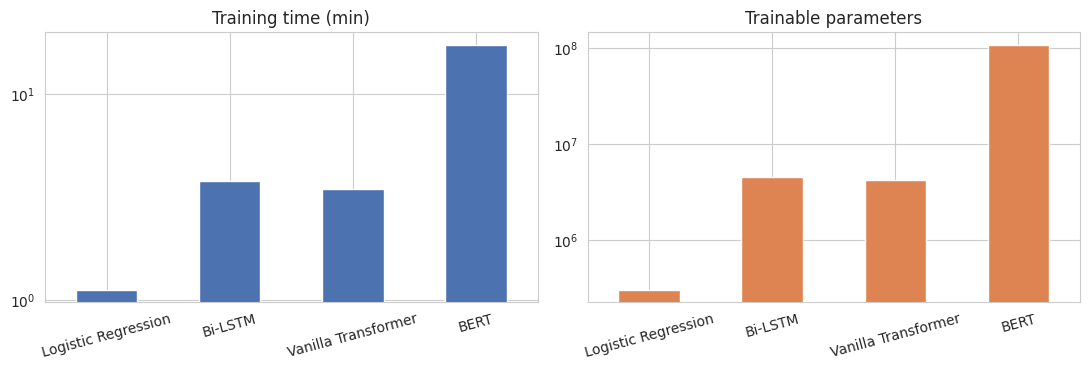

In [20]:
eff = pd.DataFrame({m: dict(Parameters=RESULTS[m]["params"],
                            Train_time_min=RESULTS[m]["train_time_s"] / 60,
                            Inference_s_per_1k_reviews=RESULTS[m]["infer_ms_per_1k"] / 1000,
                            F1=RESULTS[m]["F1"]) for m in order}).T
display(eff.style.format({"Parameters": "{:,.0f}", "Train_time_min": "{:.2f}", "Inference_s_per_1k_reviews": "{:.3f}", "F1": "{:.4f}"}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
eff["Train_time_min"].plot(kind="bar", ax=ax[0], rot=15, color="#4c72b0"); ax[0].set_title("Training time (min)"); ax[0].set_yscale("log")
eff["Parameters"].plot(kind="bar", ax=ax[1], rot=15, color="#dd8452"); ax[1].set_title("Trainable parameters"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

### 9.5 Error analysis: where do the models disagree?

Reviews misclassified by ALL four models : 117
Reviews classified correctly by ALL four : 3988
BERT right, Logistic Regression wrong     : 244
Logistic Regression right, BERT wrong     : 196


,Logistic Regression,Bi-LSTM,Vanilla Transformer,BERT
shortest 25%,0.922,0.922,0.883,0.949
25-50%,0.922,0.910,0.867,0.945
50-75%,0.902,0.916,0.876,0.929
longest 25%,0.923,0.875,0.847,0.885


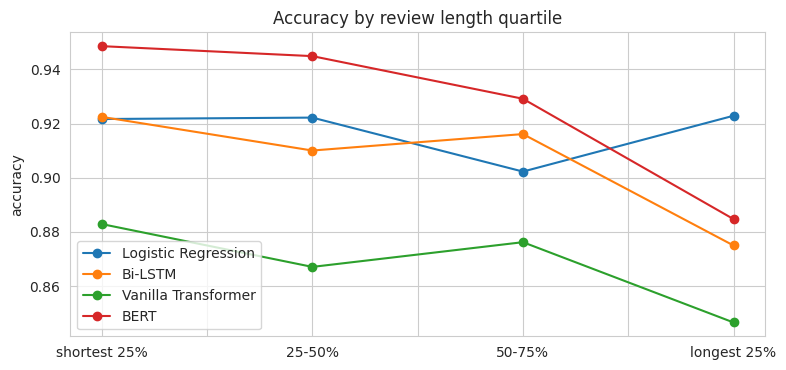

In [21]:
test_eval = test_df.reset_index(drop=True).copy()
for m in order: test_eval[m] = RESULTS[m]["y_pred"]
correct = pd.DataFrame({m: (RESULTS[m]["y_pred"] == y_test) for m in order})

print("Reviews misclassified by ALL four models :", int((~correct).all(axis=1).sum()))
print("Reviews classified correctly by ALL four :", int(correct.all(axis=1).sum()))
print("BERT right, Logistic Regression wrong     :", int((correct["BERT"] & ~correct["Logistic Regression"]).sum()))
print("Logistic Regression right, BERT wrong     :", int((~correct["BERT"] & correct["Logistic Regression"]).sum()))

# Accuracy by review length (do long reviews hurt truncated models?)
bins = pd.qcut(test_eval["n_words"], 4, labels=["shortest 25%", "25-50%", "50-75%", "longest 25%"])
by_len = correct.groupby(bins.values).mean()
display(by_len.style.format("{:.3f}"))
by_len.plot(marker="o", figsize=(8, 3.8), title="Accuracy by review length quartile"); plt.ylabel("accuracy"); plt.tight_layout(); plt.show()

In [22]:
# Hardest examples: misclassified by every model
hard = test_eval[(~correct).all(axis=1).values].head(5)
for _, r in hard.iterrows():
    print(f"TRUE: {r['sentiment']:<8} | words: {r['n_words']}")
    print(r["review"][:450] + ("..." if len(r["review"]) > 450 else "")); print("-" * 100)

# Examples BERT fixes that Logistic Regression gets wrong
fix = test_eval[(correct["BERT"] & ~correct["Logistic Regression"]).values].head(3)
print("\n#### BERT correct, Logistic Regression wrong ####")
for _, r in fix.iterrows():
    print(f"TRUE: {r['sentiment']:<8} | words: {r['n_words']}")
    print(r["review"][:450] + ("..." if len(r["review"]) > 450 else "")); print("-" * 100)

TRUE: positive | words: 164
"Slaughter High" is a totally ridiculous slasher flick about a high school nerd Marty,who gets pick on all the time by some pranksters.The prank goes wrong and he ends up getting savagely burned.Five years later his tormentors all attend a reunion-just the ten of them of course,and low and behold Marty murders them one after another.British actress Caroline Munro("Maniac")leads the cast as the heroine(who dies anyway!).The acting is completely aw...
----------------------------------------------------------------------------------------------------
TRUE: negative | words: 136
Sorry to disagree with you, but I found the DKC series to be quite engaging. So much so that I invested in the SNES system and my own copies of the games. This is, mind you, almost ten years after the initial release of DKC 1. The graphics were ground-breaking for their time, the first vector graphics games for home systems. The music and characters are all memorable, and the games brou

### 9.6 Auto-generated summary of this run

In [23]:
best = summary["F1"].idxmax(); worst = summary["F1"].idxmin()
print(f"Best model by F1 : {best} (F1 = {summary.loc[best, 'F1']:.4f})")
print(f"Weakest model    : {worst} (F1 = {summary.loc[worst, 'F1']:.4f})")
print(f"Gap best vs weakest: {100 * (summary.loc[best, 'F1'] - summary.loc[worst, 'F1']):.2f} F1 points\n")
for m in order:
    tn, fp, fn, tp = RESULTS[m]["cm"].ravel()
    bias = "over-predicts POSITIVE (more false positives)" if fp > fn else ("over-predicts NEGATIVE (more false negatives)" if fn > fp else "balanced errors")
    print(f"{m:<20} F1={RESULTS[m]['F1']:.4f}  FP={fp:<4} FN={fn:<4} -> {bias}")
gain = 100 * (summary.loc["BERT", "F1"] - summary.loc["Logistic Regression", "F1"])
cost = RESULTS["BERT"]["train_time_s"] / RESULTS["Logistic Regression"]["train_time_s"]
print(f"\nBERT vs Logistic Regression: {gain:+.2f} F1 points for ~{cost:,.0f}x the training time.")

Best model by F1 : BERT (F1 = 0.9270)
Weakest model    : Vanilla Transformer (F1 = 0.8683)
Gap best vs weakest: 5.87 F1 points

Logistic Regression  F1=0.9173  FP=243  FN=167  -> over-predicts POSITIVE (more false positives)
Bi-LSTM              F1=0.9060  FP=270  FN=196  -> over-predicts POSITIVE (more false positives)
Vanilla Transformer  F1=0.8683  FP=355  FN=298  -> over-predicts POSITIVE (more false positives)
BERT                 F1=0.9270  FP=201  FN=161  -> over-predicts POSITIVE (more false positives)

BERT vs Logistic Regression: +0.97 F1 points for ~16x the training time.


### 9.7 Discussion (read this after looking at your own numbers)

The general pattern below is what is usually seen on IMDB, but **verify each point against the tables and plots above for your run.**

1. **Logistic Regression + TF-IDF is a strong baseline.** IMDB reviews are long and rich in sentiment words, so bag-of-n-grams already reaches roughly 90% accuracy (about 91% F1 in my check of the LR part on this dataset). It trains in seconds, runs on CPU and is fully interpretable (see the top coefficients). It cannot model word order or long-range context, such as sarcasm or "not bad at all", beyond what bigrams capture.
2. **Bi-LSTM** models word order and negation, but starts from random embeddings and only 40k training reviews. It often lands close to (or slightly below / above) the TF-IDF baseline, and it is slower to train than LR. Truncation at `MAX_LEN` tokens and the sequential nature of the recurrence limit it on long reviews.
3. **Vanilla Transformer (from scratch)** has the same data limitation as the LSTM, and attention-based models are known to be data-hungry without pre-training. A small one trained from scratch on 40k reviews typically performs about the same as the LSTM and sometimes below the LR baseline. This shows that **the architecture alone does not help; pre-training does.** It trains faster than the LSTM per epoch on GPU because it is parallel over tokens.
4. **BERT** wins by a clear margin in most runs. It starts with contextual language knowledge, so it handles negation, contrast ("great cast, terrible film") and subtle phrasing. The price is about 110M parameters, the longest training time, and the slowest inference.
5. **Reading the confusion matrices:** check whether a model is biased toward one class (FP vs FN counts in 9.2). Because the classes are balanced, macro and weighted metrics are almost identical, and accuracy is meaningful here. On imbalanced data, rely on per-class recall/F1 instead.
6. **Practical recommendation:** use LR for a fast, cheap, explainable baseline or for low-resource deployment; use BERT (or a distilled variant such as DistilBERT) when accuracy matters and a GPU is available. Training LSTM/Transformer from scratch is mainly useful for learning, or when you have much more labelled data or in-domain pre-training.

## 10. Try your own review

In [24]:
@torch.no_grad()
def predict_all(text):
    text = clean_text(text); out = {}
    out["Logistic Regression"] = best_lr.predict_proba(tfidf.transform([text]))[0, 1]
    x = encode([text]).to(DEVICE)
    for name, mdl in [("Bi-LSTM", lstm_model), ("Vanilla Transformer", tf_model)]:
        mdl.eval(); out[name] = F.softmax(mdl(x), -1)[0, 1].item()
    enc = bert_tok(text, truncation=True, max_length=BERT_MAX_LEN, return_tensors="pt").to(DEVICE)
    bert.eval(); out["BERT"] = F.softmax(bert(**enc).logits.float(), -1)[0, 1].item()
    return pd.Series(out, name="P(positive)")

for s in ["This movie was a masterpiece. I loved every minute of it!",
          "Not good at all. A complete waste of two hours.",
          "I expected to hate it, but it was surprisingly not bad."]:
    print(s); display(predict_all(s).to_frame().T.style.format("{:.3f}"))

This movie was a masterpiece. I loved every minute of it!


,Logistic Regression,Bi-LSTM,Vanilla Transformer,BERT
P(positive),0.829,0.999,0.995,0.994


Not good at all. A complete waste of two hours.


,Logistic Regression,Bi-LSTM,Vanilla Transformer,BERT
P(positive),0.000,0.019,0.002,0.009


I expected to hate it, but it was surprisingly not bad.


,Logistic Regression,Bi-LSTM,Vanilla Transformer,BERT
P(positive),0.883,0.458,0.061,0.279


## 11. Save results

In [25]:
pd.concat([summary, eff.drop(columns="F1")], axis=1).to_csv("final_model_comparison.csv")
print(pd.read_csv("final_model_comparison.csv", index_col=0).round(4))
try:
    from google.colab import files
    files.download("final_model_comparison.csv")
except Exception:
    pass

                     Accuracy  Precision  Recall      F1     AUC   Parameters  \
Logistic Regression    0.9173     0.9177  0.9172  0.9173  0.9730     300001.0   
Bi-LSTM                0.9060     0.9064  0.9060  0.9060  0.9668    4499970.0   
Vanilla Transformer    0.8683     0.8685  0.8683  0.8683  0.9390    4236802.0   
BERT                   0.9270     0.9271  0.9270  0.9270  0.9791  109483778.0   

                     Train_time_min  Inference_s_per_1k_reviews  
Logistic Regression          1.1181                      0.0012  
Bi-LSTM                      3.7655                      0.1220  
Vanilla Transformer          3.4618                      0.1787  
BERT                        17.3834                      3.7461  


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>